# 6. Oversmoothing: why molecular GNNs stay shallow

**What you will learn:** what actually goes wrong when you stack graph
convolutions, how to measure it, what it costs in accuracy at 2, 4, 8 and 16
layers, and the two separate reasons molecular GNNs are nearly always three or
four layers deep.

In a convolutional network for images, deeper is famously better. In a graph
network it is usually worse, and the reason is specific and measurable.

Recall notebook 02: a graph convolution is a **local averaging** operation.
Apply an averaging operator over and over and everything converges to the same
value — the graph equivalent of stirring milk into coffee. After enough layers
every atom holds nearly the same vector, the readout sees a uniform molecule,
and the model can no longer tell a nitro group from a methyl.

This is **oversmoothing**. It was named and analysed in:

* Li, Q.; Han, Z.; Wu, X.-M. "Deeper Insights into Graph Convolutional Networks
  for Semi-Supervised Learning." AAAI 2018. DOI:
  [10.48550/arXiv.1801.07606](https://doi.org/10.48550/arXiv.1801.07606)
* Oono, K.; Suzuki, T. "Graph Neural Networks Exponentially Lose Expressive
  Power for Node Classification." ICLR 2020. DOI:
  [10.48550/arXiv.1905.10947](https://doi.org/10.48550/arXiv.1905.10947)

A second, distinct problem appears at depth too — **oversquashing**, where
information from an exponentially growing neighbourhood is crushed through a
fixed-width vector (Alon, U.; Yahav, E. "On the Bottleneck of Graph Neural
Networks and its Practical Implications." ICLR 2021. DOI:
[10.48550/arXiv.2006.05205](https://doi.org/10.48550/arXiv.2006.05205)).
They are often confused; they are not the same thing, and only the first one
is measured here.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from mgnn import features as F
from mgnn.data import WORKED_TASKS, load_tox21_graphs
from mgnn.layers import GCNLayer
from mgnn.models import MolecularGNN
from mgnn.splits import scaffold_split
from mgnn.train import evaluate, set_seed, train_model

np.set_printoptions(precision=3, suppress=True, linewidth=130)
plt.rcParams["figure.dpi"] = 110
torch.set_num_threads(4)
set_seed(0)

## 6.1 Measuring smoothness

Two numbers, both easy:

* **spread across atoms** — the standard deviation of each hidden feature
  across the atoms of a molecule, averaged over features. Zero means every
  atom is identical.
* **Dirichlet energy** — $\frac{1}{2}\sum_{(i,j) \in E} \lVert h_i - h_j
  \rVert^2$, the disagreement across bonds. This is the quantity the theory
  says decays geometrically with depth.

Both are computed on normalised representations, because a layer can also just
shrink everything towards zero — that is vanishing scale, a different disease,
and we do not want to confuse the two.

In [2]:
def spread_across_atoms(h: torch.Tensor) -> float:
    h = h / (h.norm(dim=1, keepdim=True) + 1e-9)
    return float(h.std(dim=0).mean())


def dirichlet_energy(h: torch.Tensor, edge_index: torch.Tensor) -> float:
    h = h / (h.norm(dim=1, keepdim=True) + 1e-9)
    src, dst = edge_index[0], edge_index[1]
    return float(0.5 * ((h[src] - h[dst]) ** 2).sum(dim=1).sum())


caffeine = F.smiles_to_graph("Cn1c(=O)c2c(ncn2C)n(C)c1=O")
print("caffeine:", caffeine.num_nodes, "atoms")

caffeine: 14 atoms


## 6.2 The collapse, layer by layer

Push caffeine through 20 untrained GCN layers and watch both measures fall.
Untrained is the honest place to start: oversmoothing is a property of the
*operator*, not of a bad fit.

In [3]:
set_seed(0)
hidden = 32
embed = nn.Linear(F.ATOM_FEATURE_DIM, hidden)
convs = nn.ModuleList([GCNLayer(hidden, hidden) for _ in range(20)])

h = embed(caffeine.x)
rows = [{"layer": 0, "spread": spread_across_atoms(h),
         "dirichlet": dirichlet_energy(h, caffeine.edge_index)}]
states = [h.detach().clone()]
with torch.no_grad():
    for k, conv in enumerate(convs, start=1):
        h = torch.relu(conv(h, caffeine.edge_index))
        states.append(h.detach().clone())
        rows.append({"layer": k, "spread": spread_across_atoms(h),
                     "dirichlet": dirichlet_energy(h, caffeine.edge_index)})

collapse = pd.DataFrame(rows).set_index("layer")
display(collapse.loc[[0, 1, 2, 4, 8, 12, 16, 20]].style.format("{:.4f}"))

,spread,dirichlet
layer,,
0,0.1050,9.9861
1,0.0563,3.3755
2,0.0411,1.3054
4,0.0204,0.1929
8,0.0054,0.0133
12,0.0074,0.0215
16,0.0075,0.0167
20,0.0036,0.0043


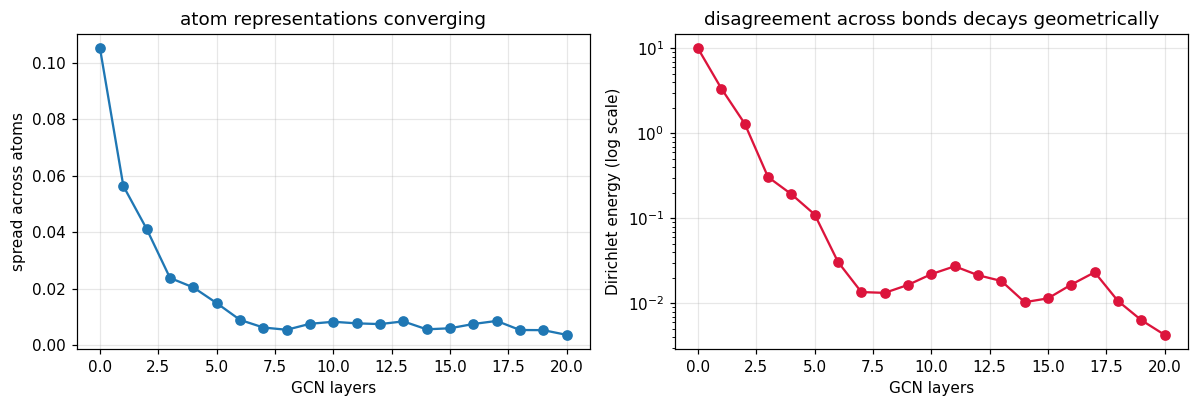

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(collapse.index, collapse["spread"], marker="o")
axes[0].set_xlabel("GCN layers"); axes[0].set_ylabel("spread across atoms")
axes[0].set_title("atom representations converging")
axes[1].semilogy(collapse.index, collapse["dirichlet"], marker="o", color="crimson")
axes[1].set_xlabel("GCN layers"); axes[1].set_ylabel("Dirichlet energy (log scale)")
axes[1].set_title("disagreement across bonds decays geometrically")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The log-scale plot is the giveaway: Dirichlet energy falls by a roughly
constant factor per layer, which is a geometric decay — exactly what Oono and
Suzuki prove. By sixteen layers the atoms of caffeine are, numerically
speaking, nearly interchangeable.

Here is the same thing as a picture. Each panel is the atom-by-atom
representation matrix at a given depth; horizontal banding means atoms differ,
a uniform wash means they do not.

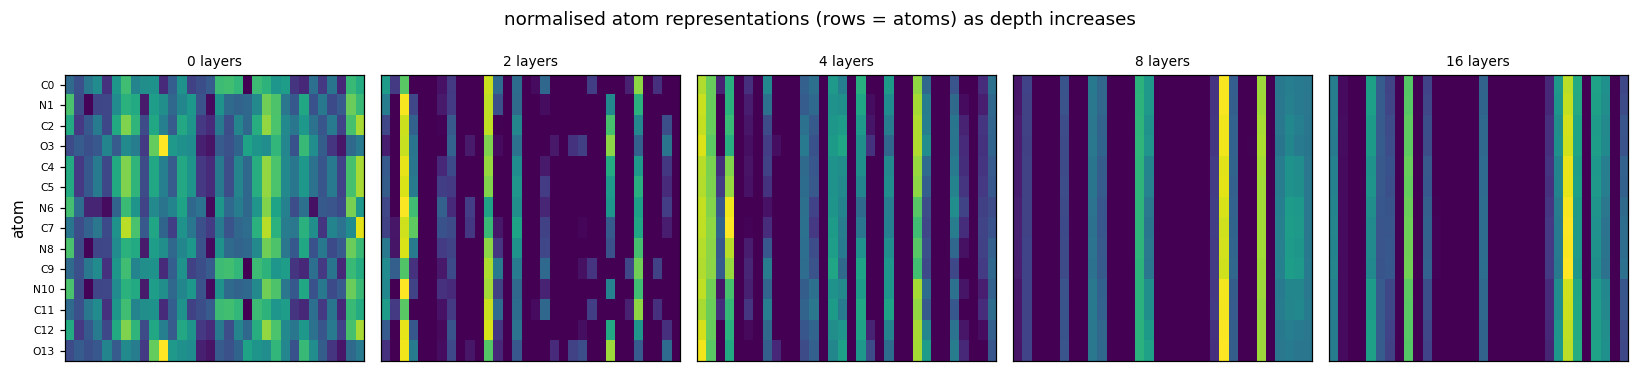

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, k in zip(axes, [0, 2, 4, 8, 16]):
    s = states[k]
    s = s / (s.norm(dim=1, keepdim=True) + 1e-9)
    ax.imshow(s.numpy(), aspect="auto", cmap="viridis")
    ax.set_title(f"{k} layers", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks(range(caffeine.num_nodes) if k == 0 else [])
    if k == 0:
        ax.set_yticklabels([f"{s_}{i}" for i, s_ in enumerate(caffeine.atom_symbols())],
                           fontsize=7)
        ax.set_ylabel("atom")
fig.suptitle("normalised atom representations (rows = atoms) as depth increases")
fig.tight_layout()
plt.show()

## 6.3 How similar do atoms actually become?

A blunter version of the same measurement: the mean pairwise cosine similarity
between atoms of the molecule. It starts well below 1 and climbs towards it.

In [6]:
def mean_pairwise_cosine(h):
    h = h / (h.norm(dim=1, keepdim=True) + 1e-9)
    sim = h @ h.T
    n = h.shape[0]
    off_diag = sim[~torch.eye(n, dtype=bool)]
    return float(off_diag.mean())

cos_rows = [{"layers": k, "mean pairwise cosine similarity": mean_pairwise_cosine(states[k])}
            for k in [0, 1, 2, 4, 8, 12, 16, 20]]
display(pd.DataFrame(cos_rows).set_index("layers").style.format("{:.4f}"))

,mean pairwise cosine similarity
layers,
0,0.5967
1,0.7940
2,0.8887
4,0.9741
8,0.9965
12,0.9940
16,0.9952
20,0.9988


## 6.4 Does it show up in accuracy? Train 2, 4, 8 and 16 layers

Everything above is geometry. The question that matters is whether it costs
predictive performance. Same data, same budget per layer, same seed, same
scaffold split: only depth changes.

To keep this notebook laptop-friendly the models train on a 1,500-molecule
subset for 12 epochs, so these are **small, single-seed numbers** — they
establish the trend and the machinery, not a definitive benchmark. Notebook 07
trains on the full split.

In [7]:
ds = load_tox21_graphs(tasks=WORKED_TASKS, verbose=False)
train_idx, valid_idx, _ = scaffold_split(ds.smiles, 0.8, 0.1, 0.1)
d_train = ds.subset(train_idx[:1500])
d_valid = ds.subset(valid_idx)
print(f"{len(d_train)} training, {len(d_valid)} validation molecules")

depths = [2, 4, 8, 16]
results = []
for residual in [False, True]:
    for depth in depths:
        set_seed(0)
        model = MolecularGNN(n_tasks=2, hidden_dim=48, n_layers=depth,
                             layer_kind="gcn", pooling="sum", dropout=0.1,
                             residual=residual)
        hist = train_model(model, d_train.graphs, d_valid.graphs, WORKED_TASKS,
                           epochs=12, batch_size=64, lr=1e-3,
                           pos_weight=torch.tensor([5.0, 3.0]),
                           verbose=False, early_stopping_patience=None)
        m = evaluate(model, d_valid.graphs, WORKED_TASKS)

        # smoothness of the trained model's own representations
        with torch.no_grad():
            states_t, final = model.node_embeddings(caffeine.x, caffeine.edge_index,
                                                    return_all_layers=True)
        results.append({
            "residual": residual, "depth": depth,
            "parameters": model.n_parameters(),
            "valid ROC-AUC": m["mean_roc_auc"],
            "NR-AR": m["per_task"]["NR-AR"]["roc_auc"],
            "SR-MMP": m["per_task"]["SR-MMP"]["roc_auc"],
            "final spread": spread_across_atoms(final),
            "best epoch": hist.best_epoch,
        })
        print(f"  residual={residual!s:<5s} depth={depth:>2d} done")

table = pd.DataFrame(results)
display(table.set_index(["residual", "depth"]).style.format({
    "valid ROC-AUC": "{:.3f}", "NR-AR": "{:.3f}", "SR-MMP": "{:.3f}",
    "final spread": "{:.4f}"}))

1500 training, 782 validation molecules


  residual=False depth= 2 done


  residual=False depth= 4 done


  residual=False depth= 8 done


  residual=False depth=16 done


  residual=True  depth= 2 done


  residual=True  depth= 4 done


  residual=True  depth= 8 done


  residual=True  depth=16 done


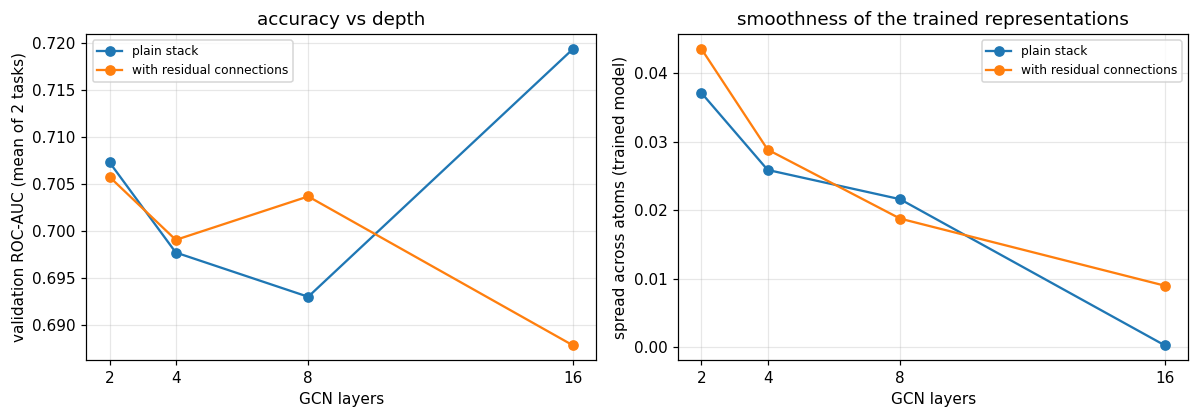

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for residual, group in table.groupby("residual"):
    lbl = "with residual connections" if residual else "plain stack"
    axes[0].plot(group["depth"], group["valid ROC-AUC"], marker="o", label=lbl)
    axes[1].plot(group["depth"], group["final spread"], marker="o", label=lbl)
axes[0].set_xlabel("GCN layers"); axes[0].set_ylabel("validation ROC-AUC (mean of 2 tasks)")
axes[0].set_title("accuracy vs depth")
axes[1].set_xlabel("GCN layers"); axes[1].set_ylabel("spread across atoms (trained model)")
axes[1].set_title("smoothness of the trained representations")
for ax in axes:
    ax.set_xticks(depths); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6.5 The second reason: molecules are small

Oversmoothing gets all the attention, but there is a plainer reason not to
stack layers on molecules. **A drug-like molecule has a tiny graph diameter.**
After three or four hops a typical atom has already seen most of the molecule,
so extra layers add receptive field that does not exist.

graph diameter over 798 Tox21 molecules:
  median 8 bonds, 90th percentile 15, max 59


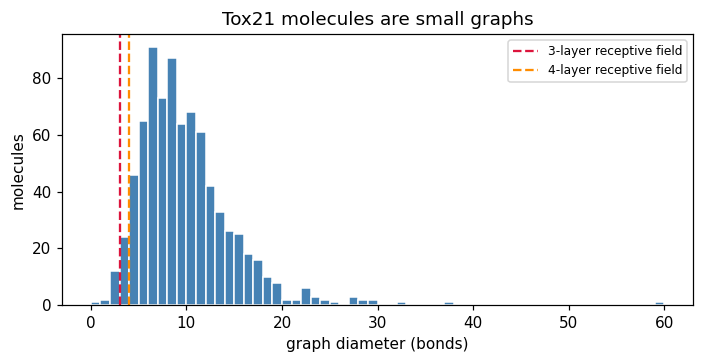

In [9]:
from rdkit import Chem  # noqa: E402

sample_smiles = ds.smiles[:800]
diameters, radii = [], []
for smi in sample_smiles:
    mol = Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms() < 2:
        continue
    D = Chem.GetDistanceMatrix(mol)
    D = D[D < 1e6]
    if D.size:
        diameters.append(float(D.max()))
Dser = pd.Series(diameters)
print(f"graph diameter over {len(Dser)} Tox21 molecules:")
print(f"  median {Dser.median():.0f} bonds, 90th percentile {Dser.quantile(0.9):.0f}, "
      f"max {Dser.max():.0f}")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.hist(Dser, bins=range(0, int(Dser.max()) + 2, 1), color="steelblue", edgecolor="white")
for k, c in [(3, "crimson"), (4, "darkorange")]:
    ax.axvline(k, color=c, ls="--", label=f"{k}-layer receptive field")
ax.set_xlabel("graph diameter (bonds)"); ax.set_ylabel("molecules")
ax.set_title("Tox21 molecules are small graphs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The fraction of molecules whose *entire* structure is within four bonds of
some atom is large. Depth beyond that mostly re-averages information the model
already has.

## 6.6 What to do instead of going deeper

When you genuinely need long-range information — a substituent at one end of a
biaryl influencing reactivity at the other — the practical options are:

1. **Residual / skip connections.** Each layer adds to its input rather than
   replacing it, so the un-smoothed signal survives. The table above shows this
   helps at depth; it delays the problem rather than removing it.
2. **Jumping knowledge** (Xu, K. et al. ICML 2018, DOI:
   [10.48550/arXiv.1806.03536](https://doi.org/10.48550/arXiv.1806.03536)) —
   concatenate the representations from *all* layers at readout, so the head
   can choose its own effective depth per atom.
3. **A virtual node** bonded to every atom: one hop to anywhere, at the cost
   of a global bottleneck.
4. **Attend to all atoms at once**, with graph distance as a bias on the
   attention — the graph-transformer answer, and, remarkably, the shape of the
   1995 architecture in notebook 09.
5. **Normalisation aimed at the problem**: PairNorm (Zhao, L.; Akoglu, L. ICLR
   2020, DOI: [10.48550/arXiv.1909.12223](https://doi.org/10.48550/arXiv.1909.12223))
   explicitly keeps node representations from collapsing together.

## What to take away

* Graph convolution is averaging; repeated averaging makes atoms identical.
  Dirichlet energy decays geometrically with depth.
* Molecular GNNs are shallow for two independent reasons: oversmoothing, and
  the fact that molecules have a diameter of about ten bonds.
* Residual connections help at depth but do not make depth free.
* If you need long-range interactions, change the connectivity (virtual node,
  all-pairs attention), not the number of layers.

**Next:** notebook 07 trains the real thing — a toxicity model on Tox21, with
a scaffold split and honest metrics.